# Predicting Single-Family Home Sale Prices in Cook County

## 1. Introduction

This project aims to predict residential sale prices using property
characteristics and location information. We focus on single-family
homes in Cook County, USA.

We will compare Ridge Regression, Random Forest, and Gradient Boosting
using the same data splits and evaluation metrics: MAE, RMSE, and R².

## 2. Data Exploration

We first examine the dataset's scope, feature meanings, missing values,
duplicate records, and unusual values to inform our preprocessing decisions.

### 2.1 Study Population and Date Coverage

In [1]:
import pandas as pd

# Load the dataset
df = pd.read_parquet("training_data.parquet")

print("Dataset shape:", df.shape)

Dataset shape: (405195, 203)


In [2]:
# Select single-family home sale records
houses = df.loc[df["meta_modeling_group"] == "SF"].copy()

# Convert sale dates to datetime
houses["meta_sale_date"] = pd.to_datetime(houses["meta_sale_date"])

print("Single-family dataset shape:", houses.shape)
print("Earliest sale date:", houses["meta_sale_date"].min())
print("Latest sale date:", houses["meta_sale_date"].max())

# Count sale records by year
annual_counts = (
    houses["meta_sale_date"]
    .dt.year
    .value_counts()
    .sort_index()
    .rename_axis("sale_year")
    .rename("number_of_sales")
)

display(annual_counts.to_frame())

Single-family dataset shape: (342547, 203)
Earliest sale date: 2017-01-01 00:00:00
Latest sale date: 2025-12-31 00:00:00


,number_of_sales
sale_year,
2017,41218
2018,41683
2019,40188
2020,42326
2021,41971
2022,39791
2023,32546
2024,30762
2025,32062


The single-family subset contains 342,547 sale records and 203 columns, covering January 2017 to December 2025.
Annual transaction counts range from 30,762 to 42,326, with fewer records from 2023 onwards.

Our tentative chronological split would contain:
- Training (2017–2023): 279,723 records
- Validation (2024): 30,762 records
- Testing (2025): 32,062 records

Feature availability at the time of prediction must be checked before finalising this setup.

In [3]:
# Reserve later years; use the tentative training period for detailed EDA
sale_year = houses["meta_sale_date"].dt.year
eda_train = houses.loc[sale_year <= 2023].copy()

# Summarise each column
column_summary = pd.DataFrame({
    "data_type": eda_train.dtypes.astype(str),
    "missing_count": eda_train.isna().sum(),
    "missing_percent": eda_train.isna().mean().mul(100),
    "unique_values": eda_train.nunique(dropna=True)
})

column_summary["missing_percent"] = (
    column_summary["missing_percent"].round(2)
)

print("Columns with missing values:",
      (column_summary["missing_count"] > 0).sum())

print("Columns with no more than one non-missing value:",
      (column_summary["unique_values"] <= 1).sum())

# Display the 20 columns with the highest missing percentages
display(
    column_summary
    .sort_values("missing_percent", ascending=False)
    .head(20)
)

Columns with missing values: 157
Columns with no more than one non-missing value: 5


,data_type,missing_count,missing_percent,unique_values
other_distressed_community_index,float64,279723,100.00,0
sv_review_json,object,279723,100.00,0
meta_tieback_key_pin,object,279138,99.79,515
loc_tax_special_service_area_num,object,272224,97.32,201
sv_outlier_reason3,object,268280,95.91,7
loc_school_unified_district_geoid,object,267259,95.54,5
loc_tax_tif_district_num,object,265855,95.04,205
sv_outlier_reason2,object,229814,82.16,8
loc_chicago_community_area_name,object,187904,67.18,76
loc_ward_num,object,184457,65.94,50


### 2.2 Missing Values and Constant Features

Within the tentative training subset, 157 columns contain missing values, and five columns have at most one distinct non-missing value.

Two columns are entirely missing: `other_distressed_community_index` and `sv_review_json`. These are candidates for exclusion.

Missing values in other columns require interpretation.
Some may indicate that a geographic or property attribute does not apply,
rather than an incomplete record. We will check feature definitions before choosing exclusion, imputation, or an explicit "not applicable" category.

Sale-review and outlier-related fields will be checked for target leakage before they are considered as model inputs.

In [4]:
# Inspect columns with at most one distinct non-missing value
display(
    column_summary.loc[column_summary["unique_values"] <= 1]
)

# Check the target and exact duplicate rows
print("Missing sale prices:",
      eda_train["meta_sale_price"].isna().sum())

print("Exact duplicate rows:",
      eda_train.duplicated().sum())

# Check whether the same property appears in multiple sale records
if "meta_pin" in eda_train.columns:
    print("Missing property IDs:",
          eda_train["meta_pin"].isna().sum())

    property_counts = eda_train["meta_pin"].value_counts()

    print("Distinct property IDs:", property_counts.size)
    print("Properties with multiple records:",
          (property_counts > 1).sum())

,data_type,missing_count,missing_percent,unique_values
meta_modeling_group,category,0,0.0,1
loc_property_state,object,279,0.1,1
char_ncu,float64,2,0.0,1
other_distressed_community_index,float64,279723,100.0,0
sv_review_json,object,279723,100.0,0


Missing sale prices: 0
Exact duplicate rows: 0
Missing property IDs: 0
Distinct property IDs: 229641
Properties with multiple records: 43676


### 2.3 Constant Features and Duplicate Records

The training subset contains no missing sale prices, no missing property IDs, and no exact duplicate rows.

Its 279,723 sale records correspond to 229,641 distinct property IDs. Of these IDs, 43,676 appear more than once. Repeated property IDs may
represent separate sales and will not be removed solely because they repeat.
We will also check property overlap across the chronological splits.

We propose excluding five input columns: `meta_modeling_group`, `loc_property_state`, `char_ncu`, `other_distressed_community_index`, and `sv_review_json`.
These columns are either entirely missing or have only one distinct non-missing value in the training subset.

In [5]:
# Examine the target and basic property characteristics
basic_columns = [
    "meta_sale_price",
    "char_bldg_sf",
    "char_beds",
    "char_yrblt"
]

display(
    eda_train[basic_columns]
    .describe(percentiles=[0.01, 0.25, 0.5, 0.75, 0.99])
    .round(2)
)

,meta_sale_price,char_bldg_sf,char_beds,char_yrblt
count,279723.00,279704.00,279694.00,279718.00
mean,354173.64,1636.28,3.20,1955.84
std,357138.56,824.48,0.84,29.68
min,10001.00,309.00,1.00,1826.00
1%,25000.00,712.00,2.00,1888.00
25%,175000.00,1100.00,3.00,1941.00
50%,270000.00,1371.00,3.00,1957.00
75%,405000.00,1923.00,4.00,1972.00
99%,1750000.00,4597.00,6.00,2018.00
max,16000000.00,17357.00,14.00,2023.00


### 2.4 Numerical Distributions

The median sale price is $270,000, compared with a mean of approximately $354,174, suggesting a right-skewed price distribution.
The middle 50% of sale prices range from $175,000 to $405,000.

The 99th percentile is $1.75 million, while the maximum is $16 million.
Extreme prices and property characteristics require further inspection; they will not be removed solely because they are large.

Building area, bedroom count, and construction year have 19, 29, and 5 missing values, respectively.

In [6]:
# Inspect the ten most expensive sale records
display(
    eda_train.nlargest(10, "meta_sale_price")[
        [
            "meta_pin",
            "meta_sale_date",
            "meta_sale_price",
            "char_bldg_sf",
            "char_beds",
            "char_yrblt"
        ]
    ]
)

# Flag construction years later than the sale year
built_after_sale = (
    eda_train["char_yrblt"]
    > eda_train["meta_sale_date"].dt.year
)

print("Records with construction year later than sale year:",
      built_after_sale.sum())

display(
    eda_train.loc[built_after_sale, [
        "meta_sale_date", "char_yrblt"
    ]].head(10)
)

,meta_pin,meta_sale_date,meta_sale_price,char_bldg_sf,char_beds,char_yrblt
324136,05214120090000,2022-07-08,16000000.0,9958.0,6.0,2014.0
122718,05161060310000,2022-08-15,12750000.0,5362.0,6.0,1904.0
122719,05161060310000,2022-08-15,12750000.0,935.0,3.0,1920.0
158368,05161060440000,2023-07-28,12500000.0,7094.0,5.0,2005.0
278406,05212020010000,2023-08-23,12250000.0,2187.0,3.0,1911.0
278407,05212020010000,2023-08-23,12250000.0,6174.0,6.0,1911.0
17964,05211040020000,2020-07-24,12000000.0,14280.0,6.0,1921.0
17965,05211040020000,2020-07-24,12000000.0,816.0,2.0,1923.0
100996,05172030380000,2018-04-24,12000000.0,9436.0,6.0,2015.0
329830,05212020150000,2022-06-12,12000000.0,7934.0,8.0,2017.0


Records with construction year later than sale year: 0


,meta_sale_date,char_yrblt


### 2.5 Extreme Prices and Multiple Rows per Sale

The ten highest-priced records include cases with the same property ID, sale date, and sale price, but different building characteristics.
These are not exact duplicate rows. Their meaning requires further investigation before deciding whether to retain or consolidate them.

No non-missing construction year is later than its corresponding sale year.
This check alone does not establish that all features were available at the time of sale.

Next, we count groups sharing the same property ID, sale date, and sale price to measure how common the multiple-row pattern is.

In [7]:
# Count rows sharing the same property ID, sale date, and sale price
sale_key = ["meta_pin", "meta_sale_date", "meta_sale_price"]

sale_group_sizes = (
    eda_train.groupby(sale_key, dropna=False)
    .size()
    .rename("row_count")
)

multiple_row_sales = sale_group_sizes[sale_group_sizes > 1]

print("Sale-key groups with multiple rows:", len(multiple_row_sales))
print("Total rows in these groups:", multiple_row_sales.sum())

# Show ten examples
display(
    multiple_row_sales
    .sort_values(ascending=False)
    .head(10)
    .reset_index()
)

Sale-key groups with multiple rows: 987
Total rows in these groups: 3036


,meta_pin,meta_sale_date,meta_sale_price,row_count
0,17293090360000,2018-06-29,1900000.0,27
1,17293090360000,2017-05-18,398000.0,27
2,17293090360000,2018-08-17,386800.0,27
3,07221040290000,2017-11-30,418460.0,26
4,07221040290000,2017-08-18,426380.0,26
5,07221040290000,2017-09-15,424750.0,26
6,07221040290000,2017-06-29,424990.0,26
7,07221040290000,2017-07-27,436870.0,26
8,07221040290000,2017-10-31,494580.0,26
9,17293090540000,2023-03-29,583000.0,24


There are 987 groups sharing the same property ID, sale date, and sale price with multiple rows.
These groups contain 3,036 records, approximately 1.09% of the training subset. The largest group contains 27 rows.

These records require further investigation before a cleaning rule is defined. 
Matching sale identifiers do not necessarily imply identical property characteristics.

In [8]:
# Inspect the largest multiple-row sale group
example = multiple_row_sales.idxmax()

group_mask = (
    (eda_train["meta_pin"] == example[0])
    & (eda_train["meta_sale_date"] == example[1])
    & (eda_train["meta_sale_price"] == example[2])
)

example_rows = eda_train.loc[group_mask]

# Identify columns whose values differ within this group
varying_columns = example_rows.columns[
    example_rows.nunique(dropna=False) > 1
]

print("Number of rows in this group:", len(example_rows))
print("Columns that differ:", varying_columns.tolist())

# Show the first ten rows of the differing columns
display(example_rows[varying_columns].head(10))

Number of rows in this group: 27
Columns that differ: ['meta_card_num', 'char_yrblt', 'char_bldg_sf', 'char_beds', 'char_fbath', 'char_hbath', 'char_type_resd', 'char_gar1_att', 'char_gar1_area', 'char_gar1_cnst', 'char_bsmt', 'char_ext_wall', 'char_bsmt_fin', 'char_roof_cnst', 'char_class']


,meta_card_num,char_yrblt,char_bldg_sf,char_beds,char_fbath,char_hbath,char_type_resd,char_gar1_att,char_gar1_area,char_gar1_cnst,char_bsmt,char_ext_wall,char_bsmt_fin,char_roof_cnst,char_class
193508,24,2008.0,2178.0,3.0,2.0,1.0,3,1,1,3,2,3,3,1,295
193509,20,2005.0,2328.0,4.0,3.0,0.0,2,2,2,1,1,2,1,1,278
193510,16,2005.0,2178.0,3.0,2.0,1.0,3,1,1,3,2,3,3,1,295
193511,5,2005.0,2328.0,4.0,3.0,0.0,2,2,2,1,1,2,1,1,278
193512,8,2005.0,2328.0,4.0,3.0,0.0,2,2,2,1,1,2,1,1,278
193513,7,2005.0,2328.0,4.0,3.0,0.0,2,2,2,1,1,2,1,1,278
193514,22,2008.0,2328.0,4.0,3.0,0.0,2,2,2,1,1,2,1,1,295
193515,6,2005.0,2226.0,4.0,3.0,0.0,2,2,2,1,1,3,3,1,278
193516,10,2005.0,2328.0,4.0,3.0,0.0,2,2,2,1,1,2,1,1,295
193517,1,2005.0,2328.0,4.0,3.0,0.0,2,2,2,1,1,2,1,1,278


### 2.6 Investigating Card-Level Records

In the selected 27-row sale group, card numbers and several property characteristics differ, including building area, bedroom count, and construction year.
These rows are therefore not exact duplicates.

Next, we check the number of distinct card numbers and the number of rows per card within this group. 
This will help clarify the record structure before we define a cleaning rule.

In [9]:
# Count distinct card numbers within the selected sale group
print("Rows in this sale group:", len(example_rows))

print("Missing card numbers:",
      example_rows["meta_card_num"].isna().sum())

print("Distinct card numbers:",
      example_rows["meta_card_num"].nunique())

# Show how many rows belong to each card number
display(
    example_rows["meta_card_num"]
    .value_counts(dropna=False)
    .rename_axis("card_number")
    .to_frame("row_count")
    .sort_index()
)

Rows in this sale group: 27
Missing card numbers: 0
Distinct card numbers: 27


,row_count
card_number,
1,1
10,1
11,1
12,1
13,1
14,1
15,1
16,1
17,1


The inspected sale group contains 27 rows and 27 distinct card numbers, with no missing card numbers. Each card appears once. 
Thus, the multiple rows in this example correspond to distinct cards rather than repeated copies of the same card.

This finding concerns one group; the structure of the remaining multiple-row sale groups still requires checking.

### 2.7 Card Counts Across Sale Groups

We now count distinct cards within each property ID, sale date, and sale price group. 
We also check for missing card numbers and repeated records sharing both the sale key and card number.

These checks will inform how we handle multi-card sales in the project.

In [10]:
# Count distinct cards in every sale group
cards_per_sale = (
    eda_train.groupby(sale_key, dropna=False)["meta_card_num"]
    .nunique()
)

print("Missing card numbers:",
      eda_train["meta_card_num"].isna().sum())

print("Sale groups with one distinct card:",
      (cards_per_sale == 1).sum())

print("Sale groups with multiple distinct cards:",
      (cards_per_sale > 1).sum())

# Check repeated combinations of sale key and card number
print("Repeated sale-key and card combinations:",
      eda_train.duplicated(
          subset=sale_key + ["meta_card_num"]
      ).sum())

Missing card numbers: 2
Sale groups with one distinct card: 276685
Sale groups with multiple distinct cards: 987
Repeated sale-key and card combinations: 0


### 2.8 Proposed Handling of Multi-Card Sales

The training subset contains 987 multi-card sale groups covering 3,036 rows.
No repeated combinations of sale key and card number were found.
Two records have missing card numbers.

For this course project, we propose restricting the modelling population to single-card sale groups with an observed card number. 
This avoids treating a shared sale price as a separate target for each card.

This restriction narrows the scope of the project and should be applied consistently across training, validation, and testing.

In [11]:
# Count rows within each sale group and align counts with original rows
rows_per_sale = (
    eda_train.groupby(sale_key, dropna=False)["meta_pin"]
    .transform("size")
)

# Keep one-row sale groups with a known card number
single_card_mask = (
    (rows_per_sale == 1)
    & eda_train["meta_card_num"].notna()
)

eda_single = eda_train.loc[single_card_mask].copy()

print("Original training rows:", len(eda_train))
print("Retained single-card rows:", len(eda_single))
print("Excluded rows:", len(eda_train) - len(eda_single))

Original training rows: 279723
Retained single-card rows: 276685
Excluded rows: 3038


The proposed restriction retains 276,685 training records and excludes 3,038 records (approximately 1.09%):
3,036 rows from multi-row sale groups and two records with missing card numbers.

Subsequent exploration uses this restricted subset. This filtering clarifies the observation structure but does not guarantee data accuracy.

### 2.9 Numerical Summary of the Restricted Subset

We recompute descriptive statistics after restricting the training data to one-row sale groups with known card numbers.
This ensures that the reported distributions describe the proposed modelling population.

In [12]:
# Recompute numerical statistics for the restricted training subset
display(
    eda_single[basic_columns]
    .describe(percentiles=[0.01, 0.25, 0.5, 0.75, 0.99])
    .round(2)
)

,meta_sale_price,char_bldg_sf,char_beds,char_yrblt
count,276685.00,276672.00,276668.00,276682.00
mean,350713.99,1632.87,3.20,1955.65
std,346024.42,819.34,0.84,29.30
min,10001.00,309.00,1.00,1826.00
1%,25000.00,720.00,2.00,1888.00
25%,175000.00,1100.00,3.00,1941.00
50%,270000.00,1368.00,3.00,1956.00
75%,400000.00,1916.00,4.00,1972.00
99%,1725000.00,4583.00,6.00,2017.00
max,16000000.00,17357.00,14.00,2023.00


### 2.10 Sale Price Distribution

The restricted training subset contains 276,685 records. The median sale price remains $270,000, while the mean is approximately $350,714.
The middle 50% of prices range from $175,000 to $400,000.

The maximum price remains $16 million, substantially above the 99th percentile of $1.725 million.
Restricting the observation structure has not removed all extreme values. 
Building area, bedroom count, and construction year have 13, 17, and 3 missing values, respectively.

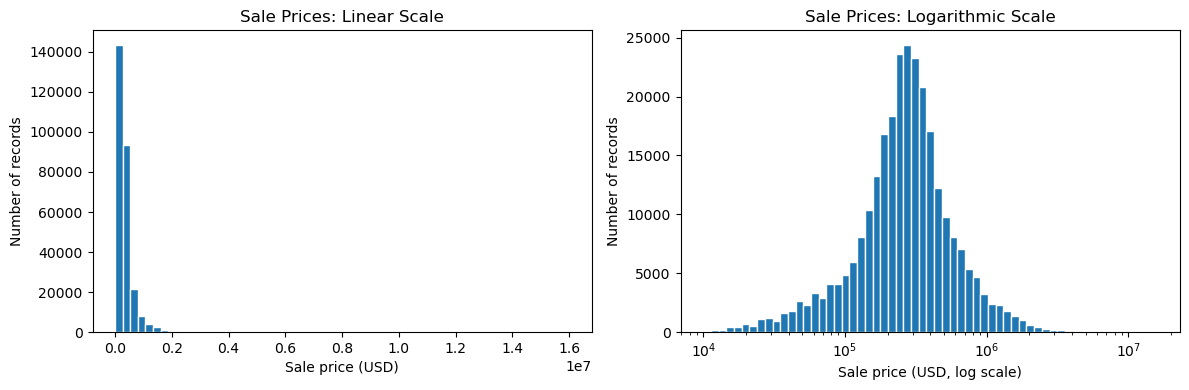

In [13]:
import numpy as np
import matplotlib.pyplot as plt

# Use all sale prices in the restricted training subset
prices = eda_single["meta_sale_price"].dropna()

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Equal-width bins on the original dollar scale
axes[0].hist(prices, bins=60, edgecolor="white")
axes[0].set_title("Sale Prices: Linear Scale")
axes[0].set_xlabel("Sale price (USD)")
axes[0].set_ylabel("Number of records")

# Log-spaced bins and a logarithmic horizontal axis
log_bins = np.geomspace(prices.min(), prices.max(), 60)
axes[1].hist(prices, bins=log_bins, edgecolor="white")
axes[1].set_xscale("log")
axes[1].set_title("Sale Prices: Logarithmic Scale")
axes[1].set_xlabel("Sale price (USD, log scale)")
axes[1].set_ylabel("Number of records")

plt.tight_layout()
plt.show()

The linear-scale plot shows that most sales are below $2 million.
Higher-price records remain present, but their bars are barely visible because their counts are small.

The logarithmic view reveals the main concentration of sale prices more clearly.
Together, the plots and summary statistics indicate a right-skewed distribution with a small number of high-price records.

### 2.11 Building Area and Sale Price

We examine the relationship between building area and sale price using a scatter plot of a reproducible random sample from the restricted training subset. 
Both axes use logarithmic scales to make the wide ranges easier to inspect.

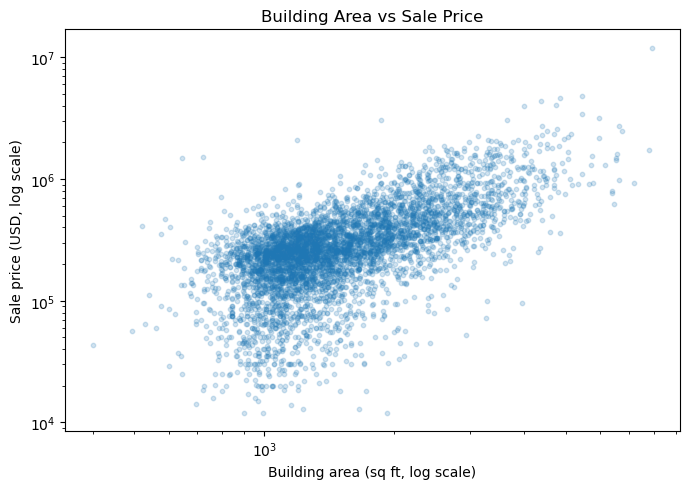

Spearman correlation: 0.618


In [14]:
# Select records with observed, positive area and price
area_price = eda_single[
    ["char_bldg_sf", "meta_sale_price"]
].dropna()

area_price = area_price.loc[
    (area_price["char_bldg_sf"] > 0)
    & (area_price["meta_sale_price"] > 0)
]

# Sample records to keep the plot readable
plot_sample = area_price.sample(
    n=min(5000, len(area_price)),
    random_state=42
)

# Plot building area against sale price
plt.figure(figsize=(7, 5))

plt.scatter(
    plot_sample["char_bldg_sf"],
    plot_sample["meta_sale_price"],
    alpha=0.2,
    s=10
)

plt.xscale("log")
plt.yscale("log")
plt.xlabel("Building area (sq ft, log scale)")
plt.ylabel("Sale price (USD, log scale)")
plt.title("Building Area vs Sale Price")
plt.tight_layout()
plt.show()

area_price_correlation = area_price.corr(method="spearman").loc[
    "char_bldg_sf", "meta_sale_price"
]

print("Spearman correlation:", round(area_price_correlation, 3))

The scatter plot shows an overall positive association between building area and sale price, consistent with a Spearman correlation of 0.618.

However, prices vary substantially among homes of similar size.
Building area is therefore a useful candidate predictor, but additional property and location features are needed to capture price differences.

### 2.12 Feature Review

We review the available fields before selecting model inputs.
Each candidate feature will be checked for its meaning, data quality, and availability at prediction time. 
Identifiers and information derived from the target will be excluded from the model inputs.

In [15]:
# List all available fields for review
for column in eda_single.columns:
    print(column)

meta_sale_price
meta_sale_date
meta_sale_document_num
meta_sale_deed_type
meta_sale_seller_name
meta_sale_buyer_name
meta_sale_count_past_n_years
meta_pin
meta_pin10
meta_year
meta_class
meta_modeling_group
meta_triad_name
meta_triad_code
meta_township_name
meta_township_code
meta_nbhd_code
meta_tax_code
meta_tieback_key_pin
meta_tieback_proration_rate
ind_pin_is_prorated
meta_card_num
ind_pin_is_multicard
meta_pin_num_cards
ind_pin_is_multiland
meta_pin_num_landlines
hie_num_active
meta_cdu
meta_mailed_bldg
meta_mailed_land
meta_mailed_tot
meta_certified_bldg
meta_certified_land
meta_certified_tot
meta_board_bldg
meta_board_land
meta_board_tot
meta_1yr_pri_board_bldg
meta_1yr_pri_board_land
meta_1yr_pri_board_tot
meta_2yr_pri_board_bldg
meta_2yr_pri_board_land
meta_2yr_pri_board_tot
loc_property_address
loc_property_city
loc_property_state
loc_property_zip
loc_longitude
loc_latitude
loc_x_3435
loc_y_3435
char_yrblt
char_bldg_sf
char_land_sf
char_beds
char_rooms
char_fbath
char_hbath
c

Candidate inputs include property characteristics, geographic information, and contextual features, subject to checking their definitions and timing.
Identifiers, sale-review outputs, and existing assessed values are excluded from the initial input set.

The earlier filter retained one-row sale groups. 
We now inspect the explicit card-count fields, because one observed row does not necessarily establish that a property has only one card.

In [16]:
# Inspect explicit card information in the retained subset
display(
    eda_single[
        ["ind_pin_is_multicard", "meta_pin_num_cards"]
    ].value_counts(dropna=False).to_frame("number_of_records")
)

,,number_of_records
ind_pin_is_multicard,meta_pin_num_cards,
False,1.0,276685


All 276,685 retained records have `ind_pin_is_multicard = False` and `meta_pin_num_cards = 1`. 
The explicit card fields therefore confirm the single-card status of the retained training subset.

### 2.13 Property Feature Candidates

We inspect the data types, missingness, and distinct-value counts of property-characteristic fields in the restricted training subset.
These fields are candidates, not yet the final model inputs.

In [17]:
# Identify property-characteristic columns
property_columns = [
    column for column in eda_single.columns
    if column.startswith("char_")
]

# Summarise candidate property features
property_summary = pd.DataFrame({
    "data_type": eda_single[property_columns].dtypes.astype(str),
    "missing_percent": (
        eda_single[property_columns].isna().mean() * 100
    ).round(2),
    "unique_values": eda_single[property_columns].nunique()
})

display(property_summary)

,data_type,missing_percent,unique_values
char_yrblt,float64,0.00,175
char_bldg_sf,float64,0.00,5565
char_land_sf,float64,0.00,20613
char_beds,float64,0.01,13
char_rooms,float64,0.01,27
char_fbath,float64,0.01,10
char_hbath,float64,0.00,8
char_frpl,float64,0.24,10
char_type_resd,category,0.15,6
char_cnst_qlty,category,0.01,3


Most property-characteristic fields have low missingness. Numerical measurements and categorical attributes are retained as candidates.

`char_apts` and `char_ncu` are excluded because each has only one distinct non-missing value in the restricted training subset.
For the initial feature set, we also omit the relatively incomplete `char_tp_dsgn` and `char_tp_plan` fields.

Renovation and percentile-derived fields are deferred pending clarification of their definitions and timing. 
These choices define an initial candidate set rather than establish historical feature availability.

In [18]:
# Define exclusions from the initial property feature candidates
excluded_property_columns = [
    "char_apts",
    "char_ncu",
    "char_tp_dsgn",
    "char_tp_plan",
    "char_recent_renovation",
    "char_land_sf_95_percentile",
    "char_bldg_sf_95_percentile"
]

# Retain the remaining property fields as candidates
property_features = [
    column for column in property_columns
    if column not in excluded_property_columns
]

print("Number of candidate property features:", len(property_features))
print(property_features)

Number of candidate property features: 25
['char_yrblt', 'char_bldg_sf', 'char_land_sf', 'char_beds', 'char_rooms', 'char_fbath', 'char_hbath', 'char_frpl', 'char_type_resd', 'char_cnst_qlty', 'char_attic_fnsh', 'char_gar1_att', 'char_gar1_area', 'char_gar1_size', 'char_gar1_cnst', 'char_attic_type', 'char_bsmt', 'char_ext_wall', 'char_heat', 'char_bsmt_fin', 'char_roof_cnst', 'char_class', 'char_use', 'char_porch', 'char_air']


### 2.14 Location and Contextual Feature Candidates

We inspect geographic, environmental, proximity, and parcel-shape fields.
These may capture price differences between homes with similar physical characteristics. 
Their definitions and temporal availability still require review before final inclusion.

In [19]:
# Identify location, proximity, and parcel-shape fields
context_columns = [
    column for column in eda_single.columns
    if column.startswith(("loc_", "prox_", "shp_"))
]

# Summarise their completeness and variation
context_summary = pd.DataFrame({
    "data_type": eda_single[context_columns].dtypes.astype(str),
    "missing_percent": (
        eda_single[context_columns].isna().mean() * 100
    ).round(2),
    "unique_values": eda_single[context_columns].nunique()
})

# Display all candidate fields, including those normally hidden by pandas
with pd.option_context("display.max_rows", None):
    display(context_summary)

,data_type,missing_percent,unique_values
loc_property_address,object,0.00,228238
loc_property_city,object,0.00,137
loc_property_state,object,0.08,1
loc_property_zip,object,0.35,173
loc_longitude,float64,0.00,240104
loc_latitude,float64,0.00,240106
loc_x_3435,float64,0.00,240099
loc_y_3435,float64,0.00,240107
loc_census_puma_geoid,object,0.00,70
loc_census_tract_geoid,object,0.00,1324


Most location and proximity fields have low missingness.
We retain a candidate set covering geographic location, environmental conditions, accessibility, proximity, and parcel geometry.

The initial set omits raw addresses, the constant state field, an alternative coordinate representation, and the high-cardinality subdivision identifier. 
Selected incomplete fields are also deferred for simplicity; their missingness is not automatically interpreted as an error.

Census-version fields and selected time-sensitive contextual measures require further review.
All retained contextual fields remain provisional until their definitions and timing have been checked.

In [20]:
# Define fields deferred from the initial contextual candidates
excluded_context_columns = [
    "loc_property_address",
    "loc_property_state",
    "loc_x_3435",
    "loc_y_3435",
    "loc_misc_subdivision_id",
    "loc_ward_num",
    "loc_chicago_community_area_name",
    "loc_school_unified_district_geoid",
    "loc_tax_special_service_area_num",
    "loc_tax_tif_district_num",
    "prox_avg_school_rating_in_half_mile",
    "prox_nearest_road_highway_speed_limit",
    "prox_num_foreclosure_per_1000_pin_past_5_years",
    "prox_nearest_new_construction_dist_ft",
    "prox_nearest_vacant_land_dist_ft"
]

# Keep remaining fields, while deferring census-related fields
context_features = [
    column for column in context_columns
    if column not in excluded_context_columns
    and not column.startswith("loc_census_")
]

print("Candidate property features:", len(property_features))
print("Candidate contextual features:", len(context_features))
print("Combined candidate count:",
      len(property_features) + len(context_features))

Candidate property features: 25
Candidate contextual features: 56
Combined candidate count: 81


### 2.15 Temporal Information Check

Our proposed split uses sale dates: 2017–2023 for training, 2024 for validation, and 2025 for testing.

We inspect the other year fields to clarify the timing of property and contextual information.
A chronological sale split alone does not guarantee that every predictor was available at the time of sale.

In [21]:
# Inspect year metadata without changing the candidate feature list
year_columns = [
    "meta_year",
    "year",
    "loc_census_data_year",
    "loc_census_acs5_data_year"
]

for column in year_columns:
    print(f"\n{column}:")
    print(eda_single[column].value_counts(dropna=False).sort_index())


meta_year:
meta_year
2017    40471
2018    41293
2019    39752
2020    41868
2021    41641
2022    39477
2023    32183
Name: count, dtype: int64

year:
year
2017    40471
2018    41293
2019    39752
2020    41868
2021    41641
2022    39477
2023    32183
Name: count, dtype: int64

loc_census_data_year:
loc_census_data_year
2017    40470
2018    41291
2019    39752
2020    41868
2021    41641
2022    39477
2023    32183
None        3
Name: count, dtype: int64

loc_census_acs5_data_year:
loc_census_acs5_data_year
2017    40470
2018    41291
2019    39752
2020    41868
2021    41641
2022    39477
2023    32183
None        3
Name: count, dtype: int64


The inspected year fields contain values from 2017 to 2023.
Both census-related year fields have three missing values.
We next compare these fields with the sale year record by record.
Matching year labels alone do not establish when the underlying information became available.

In [22]:
# Compare each metadata year with its corresponding sale year
sale_year = eda_single["meta_sale_date"].dt.year

for column in year_columns:
    field_year = pd.to_numeric(eda_single[column], errors="coerce")

    mismatches = (
        field_year.notna()
        & (field_year != sale_year)
    )

    print(
        column,
        "| Missing:", field_year.isna().sum(),
        "| Different from sale year:", mismatches.sum()
    )

meta_year | Missing: 0 | Different from sale year: 0
year | Missing: 0 | Different from sale year: 0
loc_census_data_year | Missing: 3 | Different from sale year: 0
loc_census_acs5_data_year | Missing: 3 | Different from sale year: 0


All non-missing year fields match the corresponding sale year.
`meta_year` and `year` have no missing values; each census-related year field has three missing values.

This confirms consistency of the year labels, but does not establish the publication or update dates of every contextual feature.

### 2.16 Numerical and Categorical Inputs

We separate candidate inputs into numerical and categorical fields.
This distinction guides missing-value handling and model-specific preprocessing. 
Storage types provide an initial classification; coded variables still require a semantic check.

In [23]:
# Combine the two candidate feature lists
candidate_features = property_features + context_features

# Initially classify fields by their stored data types
numeric_features = (
    eda_single[candidate_features]
    .select_dtypes(include="number")
    .columns.tolist()
)

categorical_features = [
    column for column in candidate_features
    if column not in numeric_features
]

print("Numerical candidate count:", len(numeric_features))
print(numeric_features)

print("\nCategorical candidate count:", len(categorical_features))
print(categorical_features)

Numerical candidate count: 54
['char_yrblt', 'char_bldg_sf', 'char_land_sf', 'char_beds', 'char_rooms', 'char_fbath', 'char_hbath', 'char_frpl', 'loc_longitude', 'loc_latitude', 'loc_env_flood_fs_factor', 'loc_env_flood_fs_risk_direction', 'loc_env_airport_noise_dnl', 'loc_access_cmap_walk_nta_score', 'loc_access_cmap_walk_total_score', 'prox_num_pin_in_half_mile', 'prox_num_bus_stop_in_half_mile', 'prox_num_school_in_half_mile', 'prox_num_school_with_rating_in_half_mile', 'prox_airport_dnl_total', 'prox_nearest_bike_trail_dist_ft', 'prox_nearest_cemetery_dist_ft', 'prox_nearest_cta_route_dist_ft', 'prox_nearest_cta_stop_dist_ft', 'prox_nearest_golf_course_dist_ft', 'prox_nearest_grocery_store_dist_ft', 'prox_nearest_hospital_dist_ft', 'prox_lake_michigan_dist_ft', 'prox_nearest_major_road_dist_ft', 'prox_nearest_metra_route_dist_ft', 'prox_nearest_metra_stop_dist_ft', 'prox_nearest_park_dist_ft', 'prox_nearest_railroad_dist_ft', 'prox_nearest_road_arterial_daily_traffic', 'prox_neares

The 81 candidate features consist of 54 numerical fields and 27 categorical fields, based on their storage types.

Numerical inputs include property size, room counts, coordinates, and distances to nearby facilities. 
Categorical inputs include property characteristics, geographic categories, and road surface types.

This classification is provisional: numerical codes may represent categories and should be checked against the data documentation.

### 2.17 Missing Values in Candidate Features

We examine missing values in the selected candidate features using the training-period data only.
This helps us propose imputation rules for the shared preprocessing pipeline.

In [24]:
# Summarise missing values in the candidate features
candidate_missing = pd.DataFrame({
    "missing_count": eda_single[candidate_features].isna().sum(),
    "missing_percent": (
        eda_single[candidate_features].isna().mean() * 100
    )
})

# Display only features with missing values
display(
    candidate_missing
    .loc[candidate_missing["missing_count"] > 0]
    .sort_values("missing_percent", ascending=False)
    .round(2)
)

,missing_count,missing_percent
prox_nearest_road_collector_speed_limit,50469,18.24
char_gar1_cnst,32243,11.65
prox_nearest_road_highway_daily_traffic,29937,10.82
prox_nearest_road_collector_daily_traffic,2487,0.90
loc_property_zip,982,0.35
...,...,...
shp_parcel_edge_len_ft_sd,3,0.00
shp_parcel_mrr_side_ratio,3,0.00
shp_parcel_mrr_area_ratio,3,0.00
shp_parcel_num_vertices,3,0.00


### 2.18 Proposed Missing-Value Handling

Of the 81 candidate features, 77 contain at least one missing value.
The highest missing rates are 18.24% for collector-road speed limits, 11.65% for garage construction type, and 10.82% for highway traffic.

We propose median imputation for numerical features and a separate "Missing" category for categorical features. 
Missing values are not automatically interpreted as zero or as the absence of a facility.

Imputation parameters will be fitted on the training set only and then applied unchanged to the validation and test sets.

### 2.19 Property Overlap Across Time Periods

A property may be sold multiple times and appear in different time periods. 
We check whether properties in 2024 and 2025 were also observed in the training period.

This check uses property IDs only, without examining later-period sale prices.
The results are provisional because the final eligibility rules have not yet been applied to the later periods.

In [25]:
# Extract the sale year
sale_year = houses["meta_sale_date"].dt.year

# Collect distinct property IDs for each period
train_ids = set(eda_single["meta_pin"].dropna())

validation_ids = set(
    houses.loc[sale_year == 2024, "meta_pin"].dropna()
)

test_ids = set(
    houses.loc[sale_year == 2025, "meta_pin"].dropna()
)

# Identify properties shared with the training period
validation_overlap = validation_ids & train_ids
test_overlap = test_ids & train_ids

# Summarise the overlap
overlap_summary = pd.DataFrame({
    "period": ["Validation (2024)", "Test (2025)"],
    "distinct_properties": [
        len(validation_ids),
        len(test_ids)
    ],
    "properties_seen_in_training": [
        len(validation_overlap),
        len(test_overlap)
    ]
})

overlap_summary["overlap_percent"] = (
    overlap_summary["properties_seen_in_training"]
    / overlap_summary["distinct_properties"]
    * 100
).round(2)

display(overlap_summary)

,period,distinct_properties,properties_seen_in_training,overlap_percent
0,Validation (2024),29527,8566,29.01
1,Test (2025),30493,8128,26.66


In the preliminary overlap check, 8,566 of the 29,527 distinct properties in 2024 (29.01%) and 8,128 of the 30,493 distinct properties in 2025 (26.66%) also appear in the filtered training data.

This overlap can reflect repeat sales rather than duplicate records.
We retain the chronological split because our task is to predict later sales, including sales of previously observed properties.
Property IDs will not be used as model inputs.

The evaluation therefore does not measure performance exclusively on unseen properties. 
These overlap rates will be recalculated after applying the final eligibility rules to all periods.

### 2.20 EDA Summary and Shared Modelling Protocol

#### Scope and Data Quality
Our task is to predict sale prices of single-card, single-family
properties in Cook County.

The 2017–2023 single-family subset contains 279,723 records.
After excluding multi-row sale groups and records with missing
card numbers, 276,685 records remain. The explicit property
indicators confirm that all retained records have one card.

There are no missing target values or exact duplicate rows in
the initial training-period subset. These checks do not guarantee
that all remaining records are error-free.

#### Main Findings
Sale prices are strongly right-skewed: the median is $270,000,
while the mean is approximately $350,714 in the filtered subset.
High prices are retained rather than automatically treated as errors.

Building area has a positive association with sale price
(Spearman correlation: 0.618). However, substantial price variation
remains, supporting the use of additional property and location features.

#### Shared Input Features
For our initial model comparison, we select 81 input features:
25 property features and 56 contextual features.

After the adjustment in Section 2.21, the shared feature lists
contain 53 numerical and 28 categorical inputs.

Property identifiers, the target sale price, sale-validation fields,
and assessment-value fields are excluded from model inputs.
Historical availability has not been verified for every selected
feature; this limitation is documented in Section 2.24.

#### Shared Preparation and Evaluation
The same eligibility rules are applied to all three periods.
The chronological split contains:

- Training (2017–2023): 276,685 records
- Validation (2024): 30,545 records
- Final testing (2025): 31,535 records

Numerical missing values will be filled using training-set medians.
Categorical missing values will receive a separate "Missing" category.
All learned preprocessing will be fitted on training data only.

All three models will use the same eligible records and selected
input features. Model-specific transformations may differ;
Ridge will additionally use numerical standardisation.

Each model will be tuned using the validation set. The test set
will be reserved for evaluation after model choices are fixed.
All models will report MAE, RMSE and R² on the original sale-price scale.

After final eligibility filtering, 29.09% of distinct validation
properties and 26.76% of distinct test properties were previously
observed in training. The chronological evaluation therefore
includes both previously observed and unseen properties.
Property IDs will not be used as model inputs.

### 2.21 Review of a Potentially Coded Feature

The flood-risk direction field is stored numerically, but it may represent categories rather than a continuous measurement.

We inspect its observed values before confirming its treatment.
The meanings of the codes must be checked against the data documentation.

In [26]:
# Inspect the values and their frequencies
display(
    eda_single["loc_env_flood_fs_risk_direction"]
    .value_counts(dropna=False)
    .rename_axis("stored_value")
    .to_frame("number_of_records")
)

,number_of_records
stored_value,
0.0,238843
1.0,36269
-1.0,1114
NaN,459


The field contains three observed codes (-1, 0 and 1), with 459 missing values. The meanings of these codes remain unverified.

For the provisional preprocessing plan, we treat this field as categorical to avoid imposing a fixed numerical relationship between the codes. 
This choice may be revised after documentation review.

In [27]:
# Provisionally classify the risk-direction field as categorical
coded_feature = "loc_env_flood_fs_risk_direction"

numeric_features = [
    column for column in numeric_features
    if column != coded_feature
]

if coded_feature not in categorical_features:
    categorical_features.append(coded_feature)

print("Numerical candidate count:", len(numeric_features))
print("Categorical candidate count:", len(categorical_features))

Numerical candidate count: 53
Categorical candidate count: 28


### 2.22 Shared Feature Specification
We consolidate the candidate feature lists into a shared specification.
Each feature is assigned a group, a proposed modelling type, and a missing-value handling strategy.

This specification defines the initial shared input set for all three models.
Any later feature changes must be applied consistently across models.
Temporal-availability limitations are documented in Section 2.24.

In [28]:
# Create one specification row for each candidate feature
feature_spec = pd.DataFrame({
    "feature": candidate_features
})

feature_spec["feature_group"] = feature_spec["feature"].apply(
    lambda column: (
        "Property" if column in property_features else "Contextual"
    )
)

feature_spec["modelling_type"] = feature_spec["feature"].apply(
    lambda column: (
        "Numerical" if column in numeric_features else "Categorical"
    )
)

feature_spec["missing_value_strategy"] = (
    feature_spec["modelling_type"].map({
        "Numerical": "Training-set median",
        "Categorical": "Separate Missing category"
    })
)

display(feature_spec.head(10))

print("Total candidate features:", len(feature_spec))

,feature,feature_group,modelling_type,missing_value_strategy
0,char_yrblt,Property,Numerical,Training-set median
1,char_bldg_sf,Property,Numerical,Training-set median
2,char_land_sf,Property,Numerical,Training-set median
3,char_beds,Property,Numerical,Training-set median
4,char_rooms,Property,Numerical,Training-set median
5,char_fbath,Property,Numerical,Training-set median
6,char_hbath,Property,Numerical,Training-set median
7,char_frpl,Property,Numerical,Training-set median
8,char_type_resd,Property,Categorical,Separate Missing category
9,char_cnst_qlty,Property,Categorical,Separate Missing category


Total candidate features: 81


### 2.23 Consistent Eligibility Rules and Chronological Split

We apply the same eligibility rules to all periods:
one row per sale-key group, a known card number, and property indicators confirming a single card.

We then create training, validation and test subsets by sale year.
Only subset sizes are inspected here; later-period prices are not used for feature selection or tuning.

In [29]:
# Define a sale-key group
sale_key = ["meta_pin", "meta_sale_date", "meta_sale_price"]

# Count the rows in each group across the single-family dataset
rows_per_sale_all = (
    houses.groupby(sale_key, dropna=False)["meta_pin"]
    .transform("size")
)

# Apply the agreed eligibility rules
eligible_mask = (
    (rows_per_sale_all == 1)
    & houses["meta_card_num"].notna()
    & houses["ind_pin_is_multicard"].eq(False)
    & houses["meta_pin_num_cards"].eq(1)
)

eligible_houses = houses.loc[eligible_mask].copy()

# Split eligible records by sale year
eligible_year = eligible_houses["meta_sale_date"].dt.year

train_data = eligible_houses.loc[
    eligible_year.between(2017, 2023)
].copy()

validation_data = eligible_houses.loc[
    eligible_year == 2024
].copy()

test_data = eligible_houses.loc[
    eligible_year == 2025
].copy()

print("Training records:", len(train_data))
print("Validation records:", len(validation_data))
print("Test records:", len(test_data))

# Verify that the training subset matches the earlier EDA subset
print(
    "Training rows match earlier EDA:",
    train_data.index.equals(eda_single.index)
)

Training records: 276685
Validation records: 30545
Test records: 31535
Training rows match earlier EDA: True


After applying the same eligibility rules to all periods, the split contains 276,685 training records, 30,545 validation records, and 31,535 test records.

The training subset matches the earlier EDA subset, so the training exploration remains applicable.

We recalculate property-ID overlap using the final eligible subsets.
These percentages describe distinct properties, rather than sale records.

In [30]:
# Collect distinct property IDs from the eligible subsets
train_ids = set(train_data["meta_pin"].dropna())
validation_ids = set(validation_data["meta_pin"].dropna())
test_ids = set(test_data["meta_pin"].dropna())

# Summarise overlap with training properties
final_overlap = pd.DataFrame({
    "period": ["Validation (2024)", "Test (2025)"],
    "distinct_properties": [
        len(validation_ids),
        len(test_ids)
    ],
    "properties_seen_in_training": [
        len(validation_ids & train_ids),
        len(test_ids & train_ids)
    ]
})

final_overlap["overlap_percent"] = (
    final_overlap["properties_seen_in_training"]
    / final_overlap["distinct_properties"]
    * 100
).round(2)

display(final_overlap)

,period,distinct_properties,properties_seen_in_training,overlap_percent
0,Validation (2024),29434,8561,29.09
1,Test (2025),30357,8125,26.76


After final eligibility filtering, 8,561 of the 29,434 distinct validation properties (29.09%) and 8,125 of the 30,357 distinct test properties (26.76%) were previously observed in training.

The chronological evaluation therefore includes both previously observed and unseen properties. 
Multiple sales of the same property are retained when they represent separate eligible sale records.
Property IDs will not be used as model inputs.

### 2.24 Temporal Availability and Limitations

The non-missing year labels checked during EDA match the sale year.
However, matching year labels does not establish that every input was available before the corresponding sale.

The dataset combines property records with contextual information from multiple sources.
We have not verified historical versions or publication dates for all candidate inputs.

Our project therefore compares models on the supplied dataset using a chronological sale-year split.
It should not be interpreted as a fully verified real-time forecasting system.

We exclude identifiers, sale-validation fields and assessment values from the candidate inputs.
Additional temporal uncertainty remains and will be reported as a limitation.

### 2.25 Handoff for Shared Model Development

For the initial model comparison, all three models will use the
81 selected features and the same eligible chronological subsets:
276,685 training, 30,545 validation, and 31,535 test records.

Use `candidate_features` as the shared input list. After Section 2.21,
the lists contain 53 numerical and 28 categorical features.
Section 2.22 provides the shared feature specification.

#### Yuming — EDA and Ridge Regression
Yuming has completed the initial data exploration and defined the
initial shared feature set and filtering rules. She will train and
tune Ridge Regression, analyse its results, and write the introduction,
EDA, and Ridge sections.

#### Sakura — Shared Preprocessing and Random Forest
Sakura will implement shared data preparation using the filtering
and split in Section 2.23, training-set median imputation for
numerical features, and a separate "Missing" category for
categorical features. Learned preprocessing must be fitted on
training data only.

She will also train and tune Random Forest, analyse its results,
and assemble and check the final notebook.

Model-specific transformations may differ; Ridge will additionally
use numerical standardisation.

#### Kayla — Shared Evaluation and Gradient Boosting
Kayla will review existing solutions and provide the shared evaluation
function and mean-price baseline. All models will report MAE, RMSE
and R² on the original price scale.

She will also train and tune Gradient Boosting, analyse its results,
compile the overall model comparison, and assemble the slides.

#### Shared Working Rules
Each member will tune their model using the validation set.
The test set will be reserved for evaluation after model choices
are fixed. Any changes to the shared input set or eligible records
must be coordinated across the group.

Everyone will write their own model section and prepare their own
slides. We will jointly analyse errors, write the conclusion,
and rehearse with equal presentation time.

Historical availability has not been verified for every input.
This limitation is documented in Section 2.24.